# Exploratory Data Analysis & Statistical Insights

**Dataset:** `clean_dataset.csv`, the cleaned retail transactions file produced in the previous task (Retail Store Sales, one row per transaction).

**Goal:** find patterns in sales, test three business hypotheses with statistics, and summarize the five most important findings.

**Plan**
1. Summary statistics (mean, median, standard deviation, quartiles)
2. Distributions, box plots and anomaly (outlier) detection
3. Correlation heatmap and multivariate views
4. Three hypothesis tests
5. Top 5 findings

**How to run:** upload `clean_dataset.csv` (Colab: Files panel), then click Runtime, Run all.

**Things to keep in mind**
- `total_spent` is price x quantity by construction, so strong correlations between those three columns are expected and are not a finding.
- `discount_applied` has an `Unknown` label for transactions where the flag was missing. Those rows are left out of every discount comparison.
- Profit margin columns come from assumed costs, not real costs, so they are not analysed here.

## 1. Load the data

In [38]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
ALPHA = 0.05            # significance level used for every hypothesis test

paths = (glob.glob('/content/**/clean_dataset.csv', recursive=True)
         + glob.glob('/kaggle/input/**/clean_dataset.csv', recursive=True)
         + glob.glob('./**/clean_dataset.csv', recursive=True))
assert paths, 'clean_dataset.csv not found. Upload it first, then run again.'
print('Using file:', paths[0])

df = pd.read_csv(paths[0], parse_dates=['transaction_date'])
print('Shape:', df.shape)
print('Date range:', df['transaction_date'].min().date(), 'to', df['transaction_date'].max().date())
df.head()

Using file: /content/clean_dataset.csv
Shape: (12575, 22)
Date range: 2022-01-01 to 2025-01-18


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,...,year,month,month_name,quarter,day_of_week,is_weekend,net_revenue,estimated_cost,estimated_profit,profit_margin_pct
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10,185.0,Digital Wallet,Online,2024-04-08,...,2024,4,April,2,Monday,False,166.5,129.50,37.00,22.22
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9,261.0,Digital Wallet,Online,2023-07-23,...,2023,7,July,3,Sunday,True,234.9,182.70,52.20,22.22
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2,43.0,Credit Card,Online,2022-10-05,...,2022,10,October,4,Wednesday,False,43.0,30.10,12.90,30.00
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9,247.5,Credit Card,Online,2022-05-07,...,2022,5,May,2,Saturday,True,247.5,173.25,74.25,30.00
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7,87.5,Digital Wallet,Online,2022-10-02,...,2022,10,October,4,Sunday,True,87.5,61.25,26.25,30.00


In [39]:
# Small helper used for the heatmaps below
def heatmap(ax, data, title, fmt='{:.0f}', cmap='YlGnBu', vmin=None, vmax=None):
    im = ax.imshow(data.values, cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
    ax.set_xticks(range(data.shape[1]))
    ax.set_xticklabels(data.columns, rotation=30, ha='right')
    ax.set_yticks(range(data.shape[0]))
    ax.set_yticklabels(data.index)
    mid = np.nanmean([np.nanmin(data.values), np.nanmax(data.values)])
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data.values[i, j]
            dark = (abs(v) > 0.6) if cmap == 'coolwarm' else (v > mid)
            ax.text(j, i, fmt.format(v), ha='center', va='center',
                    color='white' if dark else 'black', fontsize=9)
    ax.set_title(title)
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

def verdict(p):
    return 'statistically significant' if p < ALPHA else 'not statistically significant'

## 2. Summary descriptive statistics

In [40]:
num_cols = ['price_per_unit', 'quantity', 'total_spent']

desc = df[num_cols].describe().T
desc['median'] = df[num_cols].median()
desc['IQR'] = desc['75%'] - desc['25%']
desc['skew'] = df[num_cols].skew()
desc = desc[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'IQR', 'skew']].round(2)
desc

,count,mean,median,std,min,25%,75%,max,IQR,skew
price_per_unit,12575.0,23.37,23.0,10.75,5.0,14.0,33.5,41.0,19.5,-0.03
quantity,12575.0,5.55,6.0,2.79,1.0,3.0,8.0,10.0,5.0,-0.03
total_spent,12575.0,130.08,110.0,93.54,5.0,52.0,192.0,410.0,140.0,0.81


In [41]:
# Spread of the categorical columns (share of transactions, %)
for c in ['category', 'payment_method', 'location', 'discount_applied']:
    print(c)
    print((df[c].value_counts(normalize=True) * 100).round(1).rename_axis(None).to_string())
    print()

category
Electric Household Essentials         12.7
Furniture                             12.7
Food                                  12.6
Milk Products                         12.6
Butchers                              12.5
Beverages                             12.5
Computers And Electric Accessories    12.4
Patisserie                            12.2

payment_method
Cash              34.3
Digital Wallet    33.0
Credit Card       32.8

location
Online      50.5
In-Store    49.5

discount_applied
Yes        33.6
Unknown    33.4
No         33.1



In [42]:
# Spending by category: how much, how often, how spread out
by_cat = (df.groupby('category')['total_spent']
            .agg(transactions='count', revenue='sum', mean='mean', median='median', std='std')
            .sort_values('revenue', ascending=False))
by_cat['revenue_share_%'] = (by_cat['revenue'] / by_cat['revenue'].sum() * 100).round(1)
by_cat.round(2)

,transactions,revenue,mean,median,std,revenue_share_%
category,,,,,,
Butchers,1568,216480.5,138.06,115.00,98.92,13.2
Electric Household Essentials,1591,215297.5,135.32,112.50,94.39,13.2
Beverages,1567,206854.5,132.01,110.00,97.13,12.6
Furniture,1591,205390.0,129.09,104.00,97.39,12.6
Food,1588,205225.0,129.23,111.00,89.48,12.5
Computers And Electric Accessories,1558,202023.5,129.67,112.25,87.40,12.4
Patisserie,1528,194531.5,127.31,107.50,90.00,11.9
Milk Products,1584,189892.0,119.88,93.00,91.87,11.6


## 3. Distributions, box plots and anomalies

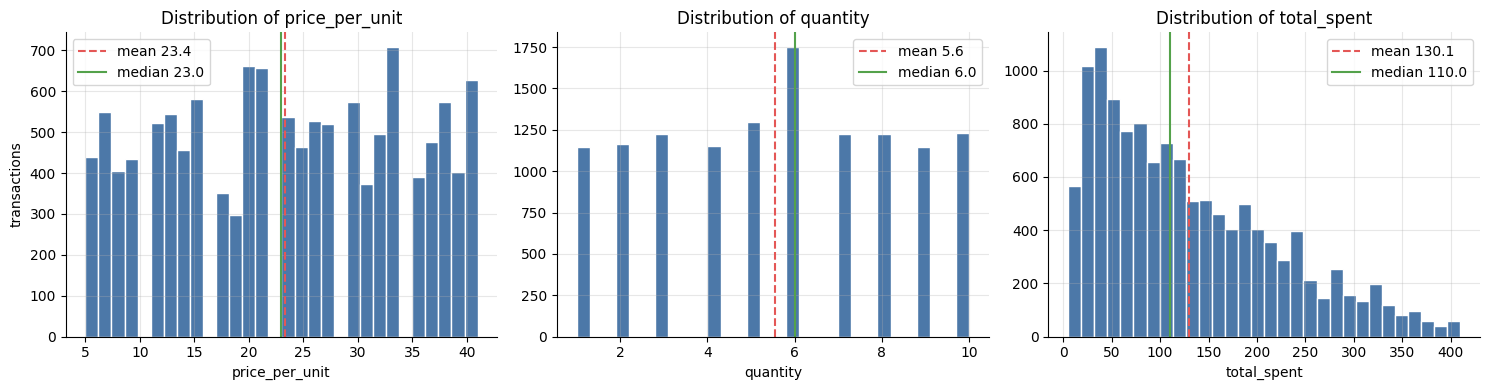

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    ax.hist(df[c], bins=30, color='#4C78A8', edgecolor='white')
    ax.axvline(df[c].mean(), color='#E45756', linestyle='--', label=f'mean {df[c].mean():.1f}')
    ax.axvline(df[c].median(), color='#54A24B', linestyle='-', label=f'median {df[c].median():.1f}')
    ax.set_title(f'Distribution of {c}')
    ax.set_xlabel(c)
    ax.legend()
axes[0].set_ylabel('transactions')
plt.tight_layout()
plt.show()

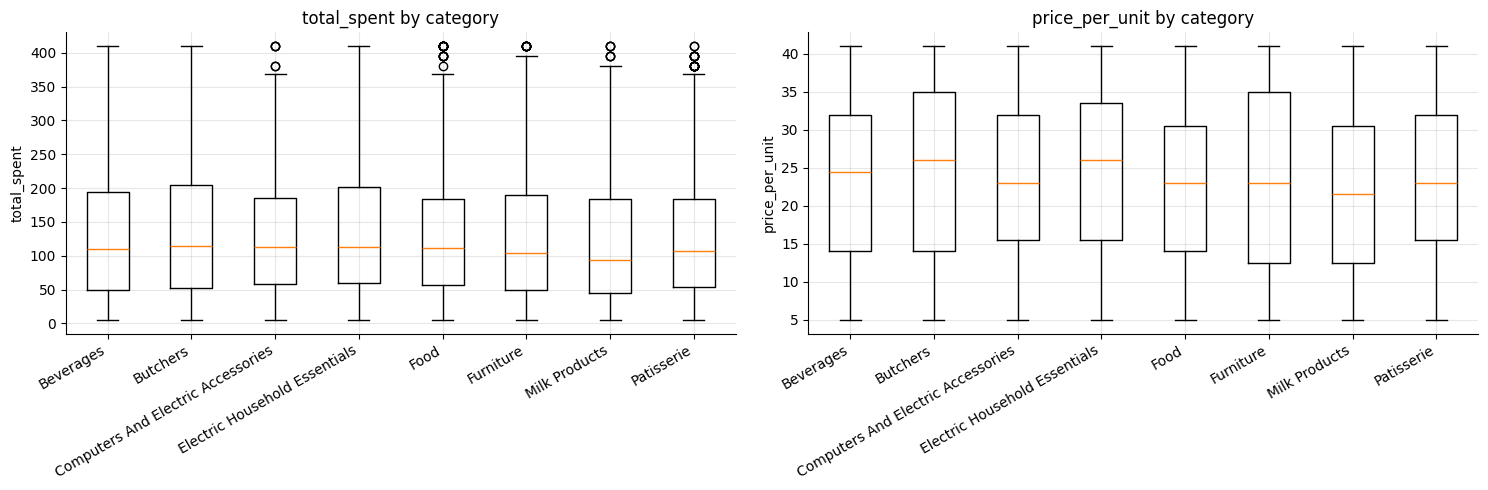

In [44]:
# Box plots: spread and outliers by category
cats = sorted(df['category'].unique())
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, c in zip(axes, ['total_spent', 'price_per_unit']):
    ax.boxplot([df.loc[df['category'] == k, c] for k in cats])
    ax.set_xticklabels(cats, rotation=30, ha='right')
    ax.set_title(f'{c} by category')
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

In [45]:
# Anomaly detection with the IQR rule (value more than 1.5 x IQR outside the quartiles)
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < low) | (df[c] > high)).sum())
    rows.append([c, round(low, 2), round(high, 2), n_out, round(n_out / len(df) * 100, 2)])
outliers = pd.DataFrame(rows, columns=['column', 'lower_fence', 'upper_fence', 'outliers', 'outliers_%'])
display(outliers)

print('Transactions flagged is_outlier during cleaning:', int(df['is_outlier'].sum()),
      f"({df['is_outlier'].mean() * 100:.1f}%)")
for c in num_cols:
    s = df[c].skew()
    shape = 'roughly symmetric' if abs(s) < 0.5 else ('right-skewed (a few large values)' if s > 0 else 'left-skewed')
    print(f'{c}: skewness {s:.2f} -> {shape}')

,column,lower_fence,upper_fence,outliers,outliers_%
0,price_per_unit,-15.25,62.75,0,0.00
1,quantity,-4.50,15.50,0,0.00
2,total_spent,-158.00,402.00,60,0.48


Transactions flagged is_outlier during cleaning: 60 (0.5%)
price_per_unit: skewness -0.03 -> roughly symmetric
quantity: skewness -0.03 -> roughly symmetric
total_spent: skewness 0.81 -> right-skewed (a few large values)


## 4. Correlation heatmap

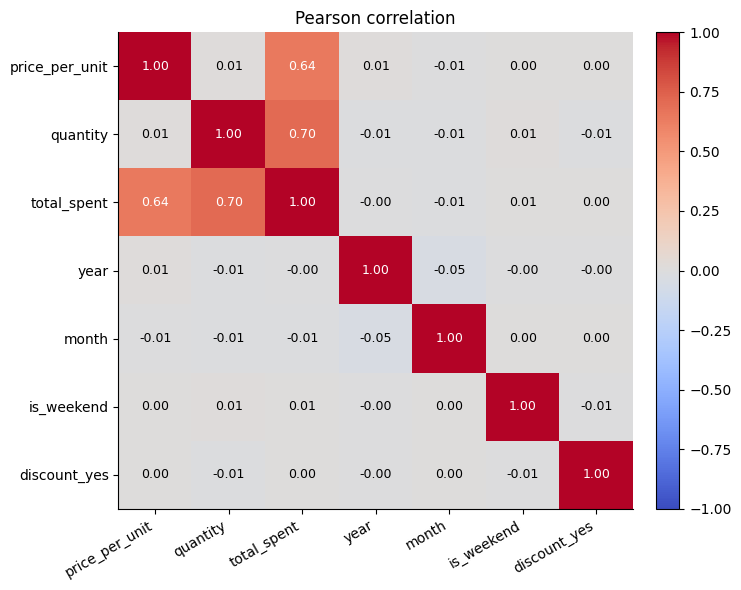

,column_1,column_2,r
15,year,month,-0.046
2,price_per_unit,year,0.012
7,quantity,year,-0.011
8,quantity,month,-0.010
9,quantity,is_weekend,0.010


In [46]:
corr_df = df[num_cols + ['year', 'month']].copy()
corr_df['is_weekend'] = df['is_weekend'].astype(int)
corr_df['discount_yes'] = df['discount_applied'].map({'Yes': 1, 'No': 0})   # Unknown stays missing
corr = corr_df.corr(method='pearson')

fig, ax = plt.subplots(figsize=(7.5, 6))
heatmap(ax, corr, 'Pearson correlation', fmt='{:.2f}', cmap='coolwarm', vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

# Strongest relationships, ignoring the ones that are true by construction
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename('r').reset_index()
pairs.columns = ['column_1', 'column_2', 'r']
structural = {frozenset(p) for p in [('price_per_unit', 'total_spent'), ('quantity', 'total_spent'),
                                      ('price_per_unit', 'quantity')]}
pairs = pairs[[frozenset((a, b)) not in structural for a, b in zip(pairs['column_1'], pairs['column_2'])]]
pairs.reindex(pairs['r'].abs().sort_values(ascending=False).index).head(5).round(3)

## 5. Multivariate views

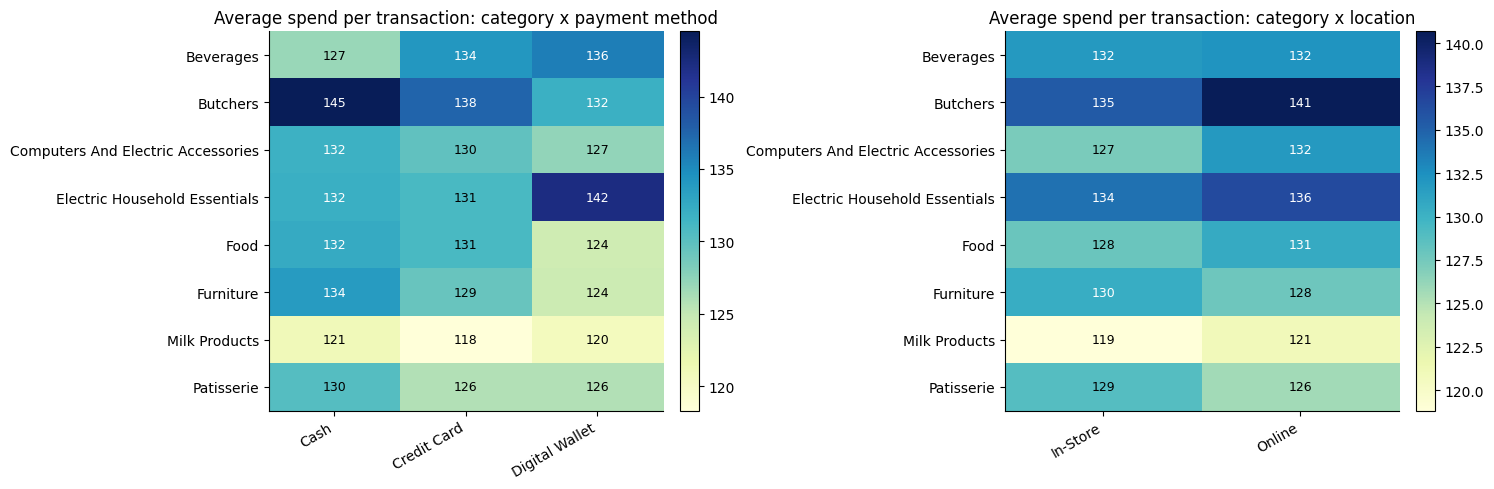

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 'Unknown' labels are placeholders for missing values, so they are left out of these views
d1 = df[(df['category'] != 'Unknown') & (df['payment_method'] != 'Unknown')]
pm = d1.pivot_table(index='category', columns='payment_method', values='total_spent', aggfunc='mean')
heatmap(axes[0], pm, 'Average spend per transaction: category x payment method')

d2 = df[(df['category'] != 'Unknown') & (df['location'] != 'Unknown')]
lm = d2.pivot_table(index='category', columns='location', values='total_spent', aggfunc='mean')
heatmap(axes[1], lm, 'Average spend per transaction: category x location')

plt.tight_layout()
plt.show()

Partly covered months left out of revenue comparisons: ['2025-01']


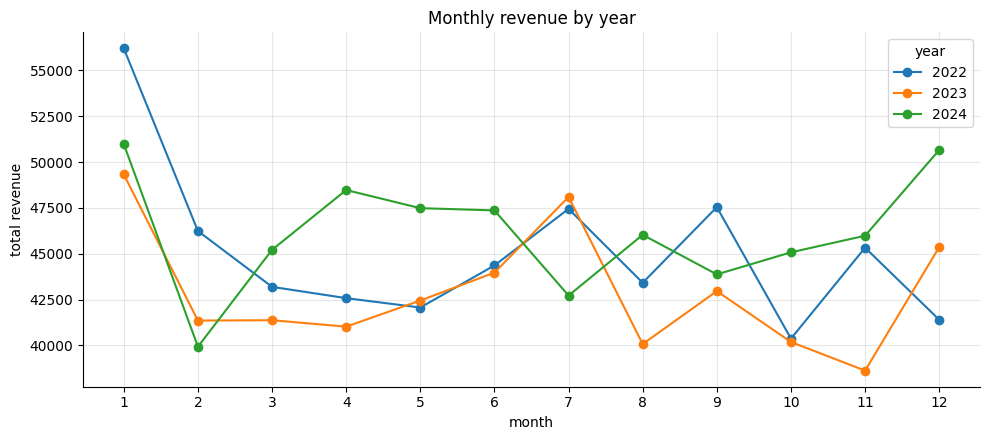

Months with full data per year:
year
2022    12
2023    12
2024    12


In [48]:
# A month that is only partly covered would look artificially low, so it is left out of revenue comparisons
first_day, last_day = df['transaction_date'].min(), df['transaction_date'].max()
df['ym'] = df['transaction_date'].dt.to_period('M')
partial = []
if first_day.day > 1:
    partial.append(first_day.to_period('M'))
if last_day.day < last_day.days_in_month:
    partial.append(last_day.to_period('M'))
full = df[~df['ym'].isin(partial)]
print('Partly covered months left out of revenue comparisons:', [str(p) for p in partial] or 'none')

# Revenue by month for each year
ym = full.groupby(['year', 'month'])['total_spent'].sum().unstack('year')

fig, ax = plt.subplots(figsize=(10, 4.5))
ym.plot(ax=ax, marker='o')
ax.set_xticks(range(1, 13))
ax.set_xlabel('month')
ax.set_ylabel('total revenue')
ax.set_title('Monthly revenue by year')
ax.legend(title='year')
plt.tight_layout()
plt.show()

print('Months with full data per year:')
print(full.groupby('year')['month'].nunique().to_string())

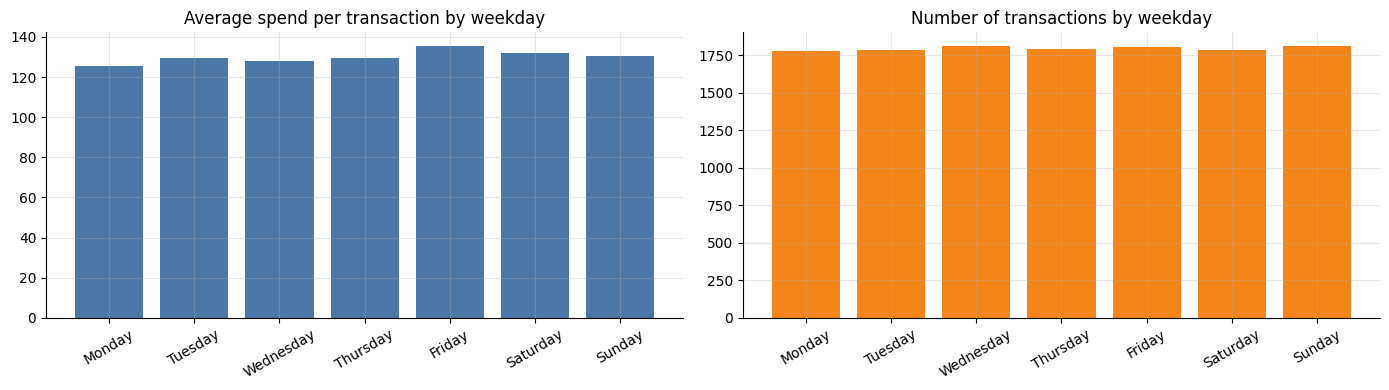

In [49]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow = df.groupby('day_of_week')['total_spent'].agg(['mean', 'count']).reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(dow.index, dow['mean'], color='#4C78A8')
axes[0].set_title('Average spend per transaction by weekday')
axes[0].tick_params(axis='x', rotation=30)
axes[1].bar(dow.index, dow['count'], color='#F58518')
axes[1].set_title('Number of transactions by weekday')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## 6. Hypothesis tests

Each test states the null (H0) and alternative (H1) hypothesis, uses a 5% significance level, and reports an effect size so that a "significant" result is also checked for practical size.

| # | Business question | Test |
|---|---|---|
| H1 | Do discounted transactions have a different spend? | Welch t-test and Mann-Whitney U |
| H2 | Do customers who get discounts more often buy more regularly (retention)? | Spearman correlation across customers |
| H3 | Does the payment method people choose depend on where they shop (online or in-store)? | Chi-square test of independence |

### H1: Discount and spend per transaction
- **H0:** average spend is the same with and without a discount.
- **H1:** average spend differs when a discount is applied.

,transactions,mean_spend,median_spend
Discount applied,4219,130.86,110.0
No discount,4157,130.64,111.0


Welch t-test: t = 0.106, p = 0.9157
Mann-Whitney U: p = 0.6857
Cohen's d (effect size) = 0.002
Result: not statistically significant at the 5% level.


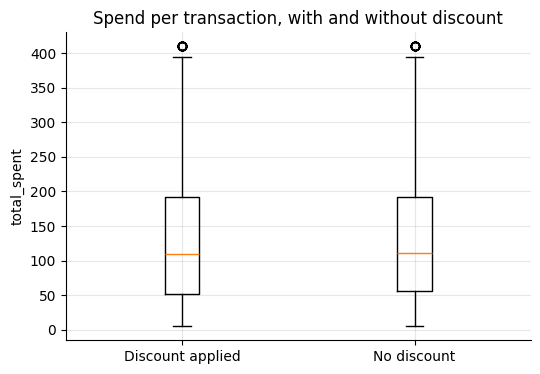

In [50]:
known = df[df['discount_applied'].isin(['Yes', 'No'])]
a = known.loc[known['discount_applied'] == 'Yes', 'total_spent']
b = known.loc[known['discount_applied'] == 'No', 'total_spent']

t_stat, p_t = stats.ttest_ind(a, b, equal_var=False)         # Welch t-test (compares means)
u_stat, p_u = stats.mannwhitneyu(a, b, alternative='two-sided')   # robust to skewed data
pooled_sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
cohens_d = (a.mean() - b.mean()) / pooled_sd

h1 = pd.DataFrame({'transactions': [len(a), len(b)], 'mean_spend': [a.mean(), b.mean()],
                   'median_spend': [a.median(), b.median()]}, index=['Discount applied', 'No discount']).round(2)
display(h1)
print(f'Welch t-test: t = {t_stat:.3f}, p = {p_t:.4f}')
print(f'Mann-Whitney U: p = {p_u:.4f}')
print(f"Cohen's d (effect size) = {cohens_d:.3f}")
print('Result:', verdict(min(p_t, p_u)), 'at the 5% level.')

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([a, b])
ax.set_xticklabels(['Discount applied', 'No discount'])
ax.set_ylabel('total_spent')
ax.set_title('Spend per transaction, with and without discount')
plt.show()

### H2: Discount frequency and customer retention
Retention is measured by purchase frequency: how many transactions each customer made (customers who keep coming back have more).
- **H0:** there is no relationship between the share of a customer's transactions that carry a discount and how often that customer buys.
- **H1:** there is a relationship (two-sided).

Customers analysed: 25
Spearman rho = 0.158, p = 0.4497
Result: not statistically significant at the 5% level.


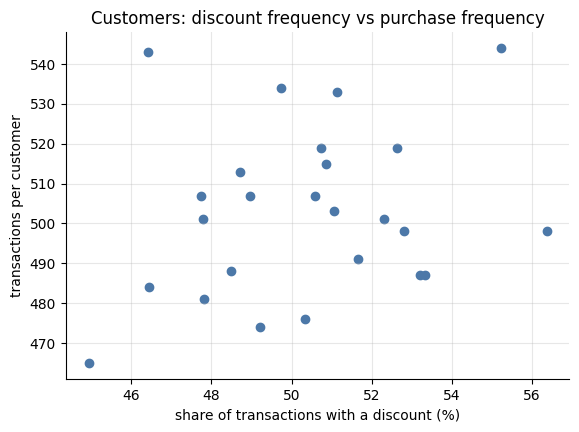

,transactions,discount_rate
customer_id,,
CUST_01,507,0.477
CUST_02,488,0.485
CUST_03,465,0.449
CUST_04,474,0.492
CUST_05,544,0.552


In [51]:
people = df[df['customer_id'] != 'Unknown']

freq = people.groupby('customer_id').size().rename('transactions')
disc_rate = (people[people['discount_applied'].isin(['Yes', 'No'])]
             .assign(has_discount=lambda d: (d['discount_applied'] == 'Yes').astype(int))
             .groupby('customer_id')['has_discount'].mean().rename('discount_rate'))
cust = pd.concat([freq, disc_rate], axis=1).dropna()

h2_ok = len(cust) >= 5 and cust['discount_rate'].nunique() > 1 and cust['transactions'].nunique() > 1
if h2_ok:
    rho, p_rho = stats.spearmanr(cust['discount_rate'], cust['transactions'])
    print('Customers analysed:', len(cust))
    print(f'Spearman rho = {rho:.3f}, p = {p_rho:.4f}')
    print('Result:', verdict(p_rho), 'at the 5% level.')
else:
    rho, p_rho = np.nan, np.nan
    print('Not enough variation between customers to run this test.')

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(cust['discount_rate'] * 100, cust['transactions'], color='#4C78A8')
ax.set_xlabel('share of transactions with a discount (%)')
ax.set_ylabel('transactions per customer')
ax.set_title('Customers: discount frequency vs purchase frequency')
plt.show()
cust.round(3).head()

### H3: Payment method and shopping channel
- **H0:** the payment method is independent of the location (online or in-store).
- **H1:** payment method and location are related.

In [52]:
sub = df[(df['payment_method'] != 'Unknown') & (df['location'] != 'Unknown')]
table = pd.crosstab(sub['location'], sub['payment_method'])
chi2, p_chi, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

print('Share of each payment method within each location (%)')
display((pd.crosstab(sub['location'], sub['payment_method'], normalize='index') * 100).round(1))
print(f'Chi-square = {chi2:.3f}, dof = {dof}, p = {p_chi:.4f}')
print(f"Cramer's V (effect size) = {cramers_v:.3f}")
print('Result:', verdict(p_chi), 'at the 5% level.')

Share of each payment method within each location (%)


payment_method,Cash,Credit Card,Digital Wallet
location,,,
In-Store,34.4,32.5,33.2
Online,34.2,33.1,32.8


Chi-square = 0.532, dof = 2, p = 0.7665
Cramer's V (effect size) = 0.007
Result: not statistically significant at the 5% level.


## 7. Top 5 findings

In [53]:
# Numbers below are computed from the results above, so the text always matches the data.
cat_rev = (df[df['category'] != 'Unknown'].groupby('category')['total_spent'].sum()
           .sort_values(ascending=False))
top_cat, low_cat = cat_rev.index[0], cat_rev.index[-1]
top_share = cat_rev.iloc[0] / cat_rev.sum() * 100
low_share = cat_rev.iloc[-1] / cat_rev.sum() * 100

# Revenue comparisons use fully covered months only (see the monthly chart above)
months_per_year = full.groupby('year')['month'].nunique()
complete_years = months_per_year[months_per_year == 12].index
year_rev = full[full['year'].isin(complete_years)].groupby('year')['total_spent'].sum()
partial_years = sorted(int(y) for y in set(df['year']) - set(complete_years))
month_avg = full.groupby(['year', 'month'])['total_spent'].sum().groupby('month').mean()
best_m, worst_m = month_avg.idxmax(), month_avg.idxmin()
month_names = {i + 1: n for i, n in enumerate(['January', 'February', 'March', 'April', 'May', 'June', 'July',
                                               'August', 'September', 'October', 'November', 'December'])}

lines = []
gap_pp = top_share - low_share
lines.append(f"**1. Revenue is spread across {len(cat_rev)} categories, led by {top_cat}.** "
             f"{top_cat} brings in {top_share:.1f}% of revenue and {low_cat} the least ({low_share:.1f}%), "
             f"a difference of {gap_pp:.1f} percentage points. "
             + ("No single category dominates, so revenue is spread almost evenly." if gap_pp < 3
                else f"{top_cat} is the category to protect, and {low_cat} the one with the most room to grow."))

season = (month_avg.max() / month_avg.min() - 1) * 100
lines.append(f"**2. Revenue changes through the year.** On average {month_names[best_m]} is the strongest month and "
             f"{month_names[worst_m]} the weakest, a difference of {season:.0f}%."
             + (f" Across the complete years, yearly revenue ranges from {year_rev.min():,.0f} ({int(year_rev.idxmin())}) "
                f"to {year_rev.max():,.0f} ({int(year_rev.idxmax())})." if len(year_rev) > 1 else '')
             + (f" {', '.join(map(str, partial_years))} is left out of these comparisons because the data covers only part of the year."
                if partial_years else ''))

lines.append(f"**3. Discounts and spend (H1): {verdict(min(p_t, p_u))}.** Average spend is {a.mean():.2f} with a discount and "
             f"{b.mean():.2f} without (Welch p = {p_t:.3f}, Cohen's d = {cohens_d:.2f}). "
             + ("Discounted transactions differ in size, but check the effect size before acting on it."
                if min(p_t, p_u) < ALPHA else "There is no evidence that discounts change how much customers spend per transaction."))

if h2_ok:
    lines.append(f"**4. Discount frequency and retention (H2): {verdict(p_rho)}.** Across {len(cust)} customers, Spearman rho = {rho:.2f} "
                 f"(p = {p_rho:.3f}). "
                 + (("Customers who get more discounts " + ("buy more often." if rho > 0 else "buy less often."))
                    if p_rho < ALPHA else "Customers who get discounts more often do not buy more often, so discounts alone are not a proven retention lever in this data."))
else:
    lines.append("**4. Discount frequency and retention (H2): could not be tested.** Customers are too similar in "
                 "purchase frequency or discount share for a correlation to be calculated.")

lines.append(f"**5. Payment method and channel (H3): {verdict(p_chi)}.** Chi-square p = {p_chi:.3f}, Cramer's V = {cramers_v:.3f}. "
             + ("Payment habits differ between online and in-store shoppers." if p_chi < ALPHA else
                "People choose payment methods in similar proportions online and in-store, so one payment mix can serve both channels.")
             + f" Separately, {df['is_outlier'].mean() * 100:.1f}% of transactions are statistical outliers and total_spent is "
               f"{'right-skewed' if df['total_spent'].skew() > 0.5 else 'fairly symmetric'} (skewness {df['total_spent'].skew():.2f}), "
               f"so medians describe a typical purchase better than means.")

display(Markdown('### Top 5 findings\n\n' + '\n\n'.join(lines)))

### Top 5 findings

**1. Revenue is spread across 8 categories, led by Butchers.** Butchers brings in 13.2% of revenue and Milk Products the least (11.6%), a difference of 1.6 percentage points. No single category dominates, so revenue is spread almost evenly.

**2. Revenue changes through the year.** On average January is the strongest month and October the weakest, a difference of 25%. Across the complete years, yearly revenue ranges from 514,798 (2023) to 553,792 (2024). 2025 is left out of these comparisons because the data covers only part of the year.

**3. Discounts and spend (H1): not statistically significant.** Average spend is 130.86 with a discount and 130.64 without (Welch p = 0.916, Cohen's d = 0.00). There is no evidence that discounts change how much customers spend per transaction.

**4. Discount frequency and retention (H2): not statistically significant.** Across 25 customers, Spearman rho = 0.16 (p = 0.450). Customers who get discounts more often do not buy more often, so discounts alone are not a proven retention lever in this data.

**5. Payment method and channel (H3): not statistically significant.** Chi-square p = 0.766, Cramer's V = 0.007. People choose payment methods in similar proportions online and in-store, so one payment mix can serve both channels. Separately, 0.5% of transactions are statistical outliers and total_spent is right-skewed (skewness 0.81), so medians describe a typical purchase better than means.

## 8. Limitations

- The data is observational, so the tests show associations, not causes.
- About a third of transactions have an unknown discount flag and are excluded from the discount tests.
- With few distinct customers, the customer-level test (H2) has limited statistical power.
- Statistical significance and practical importance are different things; the effect sizes (Cohen's d, Cramer's V) show how big the differences actually are.